## Aufbau eines Trainerskripts mit zwei Klassen:
- Trainer
- RunManager

In [1]:
#==Importe==
#Extern
import torch
from torch.utils.data import DataLoader, Subset
import torch.nn as nn
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.backends.backend_pdf import PdfPages
import copy
#Intern
from aguirre.denoiser import DenoiseTransformer
from aguirre.diffusion import DiffusionProcess
from aguirre.config import Config, RUNS_DIR, PROJECT_ROOT, CACHE_DIR
from aguirre.data import Data_coordinator
from aguirre.helpers import Akkumulator, _yaml_safe, masker

from pathlib import Path
from dataclasses import asdict, replace
from datetime import datetime
import yaml




cfg = Config()

In [2]:
"""Abschnitt 7 -- Laufverwaltung.

Der RunManager kennt nur das DATEISYSTEM: Ordner, Pfade, Namen, torch.save
und torch.load. Er kennt kein Training, keinen Optimizer, keine EMA.
Der Trainer entscheidet, WANN gespeichert wird und WAS im Dict steht --
der RunManager legt es an einen reproduzierbaren Pfad.

Ordnerlayout eines Laufs:
    runs/train_<name>_<datum>/
        config.yaml              die exakte Config dieses Laufs
        checkpoints/
            checkpoint_last.pt   wird ueberschrieben, Absturzversicherung
            checkpoint_best.pt   nur wenn best_val faellt
        final.pt                 das fertige Artefakt (save_run)
        metrics/                 CSV-Dateien, vom Trainer gefuellt

Vertrag fuer das state-Dict (der Trainer baut es, nicht der RunManager):
    "model"      Model.state_dict()
    "ema"        EMA_Model.state_dict() -- PFLICHT, gesampelt wird aus der EMA
    "opt"        optimizer.state_dict() -- nur im Checkpoint, nicht in final
    "sched"      scheduler.state_dict() oder None
    "epoch"      int, die zuletzt ABGESCHLOSSENE Epoche
                 -> fortgesetzt wird bei epoch + 1
    "best_val"   float
    "cfg"        dataclasses.asdict(cfg) -- ein einfaches Dict, KEINE Klasse.
                 torch.load nutzt seit PyTorch 2.6 weights_only=True und
                 kann eigene Klassen und Path-Objekte nicht entpacken.
"""


class RunManager:
    """Ordner, Checkpoints und Lauf-Artefakte eines Trainingslaufs."""

    #==Was ins fertige Artefakt gehoert (Whitelist, bewusst ohne opt/sched)==
    _FINAL_KEYS = ("model", "ema", "epoch", "best_val", "cfg")

    #==Keys, ohne die ein Checkpoint wertlos ist==
    _PFLICHT_KEYS = ("model", "ema")

    def __init__(self, cfg: Config, run_name: str | None = None):
        """Legt den Lauf-Ordner an und schreibt die Config hinein.

        Args:
            cfg: Config dieses Laufs.
            run_name: Kurzer Name fuer den Ordner. None -> nur Zeitstempel.
        """
        self.cfg = cfg
        self.cfg_dict = asdict(cfg)

        time_stamp = datetime.now().strftime("%Y-%m-%d_%H%M")
        if run_name is not None:
            foldername = f"train_{run_name}_{time_stamp}"
        else:
            foldername = f"train_run_{time_stamp}"

        base = RUNS_DIR / foldername

        # mkdir(exist_ok=False) ist atomar -- zwei gleichzeitig startende
        # Cluster-Jobs mit demselben Zeitstempel koennen nicht beide gewinnen.
        i = 1
        while True:
            run_dir = base if i == 1 else base.parent / f"{base.name}_{i}"
            try:
                run_dir.mkdir(parents=True, exist_ok=False)
                break
            except FileExistsError:
                i += 1
                if i > 100:
                    raise RuntimeError(
                        f"zu viele Laeufe mit Praefix {base.name}"
                    )

        self.run_dir = run_dir

        # mkdir() gibt None zurueck -- Pfad zuerst binden, dann anlegen
        self.ckpt_dir = self.run_dir / "checkpoints"
        self.metrics_dir = self.run_dir / "metrics"
        self.ckpt_dir.mkdir(parents=True, exist_ok=True)
        self.metrics_dir.mkdir(parents=True, exist_ok=True)

        # Config SOFORT schreiben: ein abgebrochener Lauf ohne config.yaml
        # ist nicht rekonstruierbar, und genau die brechen ab.
        self.config_path = self.run_dir / "config.yaml"
        with open(self.config_path, "w", encoding="utf-8") as f:
            yaml.safe_dump(
                _yaml_safe(self.cfg_dict),
                f,
                sort_keys=False,      # Feldreihenfolge der Dataclass behalten
                allow_unicode=True,   # Umlaute lesbar statt \uXXXX
            )

    #==Interne Helfer==

    def _atomic_save(self, obj, path: Path) -> Path:
        """torch.save ueber eine .tmp-Datei, dann atomar ersetzen.

        Path.replace ist auf demselben Dateisystem atomar: stirbt der Job
        mitten im Schreiben, bleibt die alte, gueltige Datei unversehrt.
        """
        tmp = path.parent / (path.name + ".tmp")
        try:
            torch.save(obj, tmp)
            tmp.replace(path)
        except Exception:
            tmp.unlink(missing_ok=True)   # keine Leiche hinterlassen
            raise
        return path

    def _check_keys(self, state: dict, keys=None) -> None:
        """Bricht ab, wenn Pflicht-Keys im state fehlen."""
        keys = self._PFLICHT_KEYS if keys is None else keys
        fehlend = [k for k in keys if k not in state]
        if fehlend:
            raise KeyError(
                f"state fehlt {fehlend}. Ohne EMA-Gewichte ist der Checkpoint "
                f"zum Sampeln wertlos. Vorhandene Keys: {sorted(state)}"
            )

    @staticmethod
    def load_config(run_dir: str | Path) -> Config:
        """config.yaml eines Laufs als Config-Objekt.

        Hinweis: YAML kennt keine Tupel -- adam_betas kommt als Liste
        zurueck. Fuer torch.optim.Adam ist das unerheblich.
        """
        with open(Path(run_dir) / "config.yaml", encoding="utf-8") as f:
            d = yaml.safe_load(f)
        return Config(**d)

    # ==== Checkpoints: waehrend des Laufs ====

    def save_checkpoint(self, state: dict, tag: str = "last") -> Path:
        """state-Dict nach checkpoints/checkpoint_<tag>.pt schreiben.

        Args:
            state: siehe Vertrag im Modul-Docstring. Nur einfache Typen --
                Tensoren, Zahlen, Strings, Listen, Dicts.
            tag: "last", "best" oder z.B. "epoch_042".

        Returns:
            Pfad der geschriebenen Datei.
        """
        self._check_keys(state)
        path = self.ckpt_dir / f"checkpoint_{tag}.pt"
        return self._atomic_save(state, path)

    def allocate_checkpoint(self, tag: str = "last", map_location="cpu") -> dict:
        """Checkpoint zurueckladen.

        Args:
            tag: "last", "best" oder z.B. "epoch_042".
            map_location: "cpu" ist der sichere Default -- ein auf CUDA
                gespeicherter Checkpoint laesst sich sonst auf einem Rechner
                ohne GPU nicht oeffnen. optimizer.load_state_dict schiebt
                die Momente ohnehin dorthin, wo die Parameter liegen.

        Returns:
            Das state-Dict, unveraendert. Das Zurueckspielen in Modell,
            Optimizer und EMA macht der Trainer -- der RunManager weiss
            nicht, was ein Modell ist.
        """
        path = self.ckpt_dir / f"checkpoint_{tag}.pt"

        if not path.is_file():
            vorhanden = sorted(
                p.stem.removeprefix("checkpoint_")
                for p in self.ckpt_dir.glob("checkpoint_*.pt")
            )
            raise FileNotFoundError(
                f"{path} existiert nicht. Vorhandene Tags: "
                f"{vorhanden if vorhanden else '(keine)'}"
            )

        state = torch.load(path, map_location=map_location)
        self._check_keys(state)
        return state

    # ==== Lauf: am Ende ====

    def save_run(self, state: dict) -> Path:
        """Fertiges Artefakt nach final.pt schreiben.

        Enthaelt bewusst NICHT den Optimizer- und Scheduler-State: zum
        Sampeln braucht man beides nie, und Adams zwei Momente machen die
        Datei etwa dreimal so gross.

        Args:
            state: dasselbe Dict wie fuer save_checkpoint. Gefiltert wird
                ueber _FINAL_KEYS.

        Returns:
            Pfad von final.pt.
        """
        self._check_keys(state)
        final = {k: state[k] for k in self._FINAL_KEYS if k in state}
        return self._atomic_save(final, self.run_dir / "final.pt")

    @staticmethod
    def load_run(run_dir: str | Path, map_location="cpu") -> dict:
        """Fertigen Lauf laden, ohne einen RunManager zu bauen.

        Statisch, weil das Laden eines alten Laufs keinen neuen Ordner
        anlegen soll.

        Returns:
            Dict mit model, ema, epoch, best_val, cfg. Das Modell baut der
            Aufrufer:
                d   = RunManager.load_run("runs/train_...")
                cfg = Config(**d["cfg"])
                m   = build_denoiser(cfg, esm_model)
                m.load_state_dict(d["ema"])      # EMA, nicht "model"
                m.eval()
        """
        run_dir = Path(run_dir)
        path = run_dir / "final.pt"

        if not path.is_file():
            ckpts = sorted((run_dir / "checkpoints").glob("checkpoint_*.pt"))
            raise FileNotFoundError(
                f"{path} existiert nicht -- der Lauf wurde vermutlich nicht "
                f"regulaer beendet. Vorhandene Checkpoints: "
                f"{[p.name for p in ckpts] if ckpts else '(keine)'}"
            )

        return torch.load(path, map_location=map_location)


In [3]:
BRAUN_BLAU = LinearSegmentedColormap.from_list(
    "braun_blau", ["#f5ead9", "#c89a62", "#7b7e97", "#3a5b86", "#15304f"]
)


class Trainer():
    """Trainingsschleife, Validierung, EMA, Checkpointing."""

    def __init__(
            self,
            Model: DenoiseTransformer,
            Train_Data: DataLoader,
            Val_Data: DataLoader,
            run_manager: RunManager,
            optimizer: torch.optim.Optimizer | None = None,
            cfg: Config = cfg,
    ):
        """
        Args:
            Model: Denoiser. Wird aufs cfg.device verschoben.
            Train_Data: DataLoader, liefert (emb, lengths).
            Val_Data: DataLoader, liefert (emb, lengths).
            run_manager: schreibt Checkpoints und Lauf-Artefakte.
            optimizer: None -> Adam aus cfg.learning_rate und cfg.adam_betas.
            cfg: Config dieses Laufs.
        """
        # Config
        self.cfg = cfg
        self.device = cfg.device
        torch.manual_seed(cfg.seed)

        # DataLoader
        self.Train_Data = Train_Data
        self.Val_Data = Val_Data

        # RunManager
        self.run_manager = run_manager
        self.plots_dir = run_manager.run_dir / "plots"
        self.plots_dir.mkdir(parents=True, exist_ok=True)

        # Modelle
        self.Model = Model.to(self.device)
        EMA_Model = copy.deepcopy(Model).to(self.device)
        EMA_Model = EMA_Model.requires_grad_(False)
        self.EMA_Model = EMA_Model

        # Mini-Val fuer t-Loss
        ds = Val_Data.dataset
        lengths = self._lengths_of(ds)
        N = len(lengths)
        n = min(max(int(self.cfg.eval_subset_fract * N), self.cfg.eval_subset_min), self.cfg.eval_subset_max)
        n = min(n, N)
        # Laengenstratifizierung
        order = torch.argsort(lengths)
        pick = (torch.arange(n) * (N / n)).long().clamp(max=N - 1)
        idx = order[pick].tolist()
        eval_ds = Subset(ds, idx)
        self.Val_Data_sub = DataLoader(eval_ds, batch_size=self.cfg.batch_size, shuffle=False)

        # Weitere Instanzen
        self.Scheduler_train = DiffusionProcess(model=self.Model, cfg=self.cfg).to(self.device)
        self.Scheduler_val = DiffusionProcess(model=self.EMA_Model, cfg=self.cfg).to(self.device)
        self.ema_weight = (1 - cfg.ema_decay)  # 1 - beta
        self.optimizer = optimizer if optimizer is not None else torch.optim.Adam(
            self.Model.parameters(),
            lr=cfg.learning_rate,
            betas=tuple(cfg.adam_betas),
        )

        # Festes t-Raster
        t_space = torch.linspace(0, cfg.timesteps - 1, int(cfg.eval_t_grid)).long()
        self.t_space = torch.unique(t_space)

        # Lauf-Zustand
        self.start_epoch = 0
        self.best_val = float("inf")
        self.history = {
            "epoch": [],
            "train_loss": [],
            "train_token_loss": [],
            "val_sequence_loss": [],
            "val_token_loss": [],
            "loss_per_t": [],
        }

    @staticmethod
    def _lengths_of(ds) -> torch.Tensor:
        """Laengen-Tensor eines Datasets, auch durch Subset-Schichten hindurch."""
        if isinstance(ds, Subset):
            return Trainer._lengths_of(ds.dataset)[torch.as_tensor(ds.indices)]
        return ds.lengths

    def _batch(self, batch):
        """(emb, lengths) -> x, padding_mask, B auf dem richtigen Device."""
        x, lengths = batch
        x = x.to(self.device)
        lengths = lengths.to(self.device)
        padding_mask = masker(lengths, pep_max_len=self.cfg.pep_max_len)
        return x, padding_mask, x.shape[0]

    def forward_train(self, x, padding_mask):
        """Ein Forward-Pass auf dem Trainingsmodell.

        Returns:
            (loss_el, t) -- (B, L, D) elementweiser Fehler, (B,) Zeitschritte.
        """
        B = x.shape[0]
        t = torch.randint(0, self.Scheduler_train.num_timesteps, (B,), device=self.device).long()
        loss_el = self.Scheduler_train.loss_elements(x_start=x, t=t, padding_mask=padding_mask)
        return loss_el, t

    def forward_val(self, x, padding_mask, generator=None):
        """Ein Forward-Pass auf dem EMA-Modell.

        Args:
            generator: fester CPU-Generator -> vergleichbare t ueber Epochen.

        Returns:
            (loss_el, t)
        """
        B = x.shape[0]
        T = self.Scheduler_val.num_timesteps
        t = torch.randint(0, T, (B,), generator=generator).long().to(self.device)
        loss_el = self.Scheduler_val.loss_elements(x_start=x, t=t, padding_mask=padding_mask)
        return loss_el, t

    def update_EMA(self):
        with torch.no_grad():
            for theta, theta_EMA in zip(self.Model.parameters(), self.EMA_Model.parameters()):
                theta_EMA.lerp_(end=theta, weight=self.ema_weight)

    def train(self, token_loss: bool = True):
        """Training ueber eine Epoch.

        Returns:
            (loss_epoch, tok_loss_epoch); der zweite Wert ist None bei
            token_loss=False.
        """
        self.Model.train()
        loss_akk = Akkumulator()
        token_loss_akk = Akkumulator()

        for batch in self.Train_Data:
            x, p_mask, B = self._batch(batch)

            self.optimizer.zero_grad()
            loss_el, t = self.forward_train(x, p_mask)
            loss = self.Scheduler_train.reduce_loss(
                loss_el=loss_el,
                padding_mask=p_mask,
                weight=self.Scheduler_train.loss_weight(t=t),
                mode=self.cfg.loss_reduction,
            )

            if token_loss:
                with torch.no_grad():
                    tok_loss = self.Scheduler_train.reduce_loss(
                        loss_el=loss_el.detach(),
                        padding_mask=p_mask,
                        weight=None,
                        mode="token",
                    )
                token_loss_akk.update(value=tok_loss.item(), n=B)

            loss.backward()
            # Clipping bei cfg.max_grad_norm, angepasst an die lucidrains-Linie,
            # auf der ampdiffusion.py aufsetzt (Default dort 1.0).
            nn.utils.clip_grad_norm_(self.Model.parameters(), self.cfg.max_grad_norm)
            self.optimizer.step()
            self.update_EMA()
            loss_akk.update(value=loss.item(), n=B)

        loss_epoch = loss_akk.compute()
        tok_loss_epoch = token_loss_akk.compute() if token_loss else None
        return loss_epoch, tok_loss_epoch

    @torch.no_grad()
    def evaluate(self, grid_value: int | None = None):
        """Evaluation ueber eine Epoch, auf dem EMA-Modell.

        t-Raster und Rauschen sind fest, damit Epochen vergleichbar sind.
        Der t-Raster-Loss laeuft bewusst ohne w(t): bei festem t ist w
        konstant und die Metrik soll von der Trainingsgewichtung unabhaengig
        bleiben.

        Returns:
            (loss_per_t, token_loss, sequence_loss) -- (n_grid,), Skalar, Skalar.
        """
        self.EMA_Model.eval()
        t_space = self.t_space if grid_value is None else torch.unique(
            torch.linspace(0, self.cfg.timesteps - 1, int(grid_value)).long()
        )

        # t-Loss
        t_loss_akk = Akkumulator()
        for t_val in t_space:
            der_g = torch.Generator(device="cpu")
            der_g.manual_seed(self.cfg.seed)

            for batch in self.Val_Data_sub:
                x, p_mask, B = self._batch(batch)
                L, D = x.shape[1], x.shape[2]
                eps_slice = torch.randn(B, L, D, generator=der_g).to(self.device)
                t = torch.full((B,), int(t_val), dtype=torch.long, device=self.device)

                loss_ele = self.Scheduler_val.loss_elements(
                    x_start=x,
                    t=t,
                    padding_mask=p_mask,
                    noise=eps_slice,
                )
                t_loss = self.Scheduler_val.reduce_loss(
                    loss_el=loss_ele,
                    padding_mask=p_mask,
                    weight=None,
                    mode="sequence",
                )
                t_loss_akk.update(value=t_loss.item(), n=B)

            t_loss_akk.compute()
            t_loss_akk.reset()

        loss_per_t = t_loss_akk.output()
        t_loss_akk.hard_reset()

        # token_loss und sequence_loss
        val_g = torch.Generator(device="cpu")
        val_g.manual_seed(self.cfg.seed)
        token_loss_akk = Akkumulator()
        sequence_loss_akk = Akkumulator()

        for batch in self.Val_Data:
            x, p_mask, B = self._batch(batch)
            loss_el, t = self.forward_val(x, p_mask, generator=val_g)

            seq_loss = self.Scheduler_val.reduce_loss(
                loss_el=loss_el,
                padding_mask=p_mask,
                weight=self.Scheduler_val.loss_weight(t=t),
                mode=self.cfg.loss_reduction,
            )
            tok_loss = self.Scheduler_val.reduce_loss(
                loss_el=loss_el,
                padding_mask=p_mask,
                weight=None,
                mode="token",
            )
            token_loss_akk.update(value=tok_loss.item(), n=B)
            sequence_loss_akk.update(value=seq_loss.item(), n=B)

        token_loss = token_loss_akk.compute()
        sequence_loss = sequence_loss_akk.compute()
        return loss_per_t, token_loss, sequence_loss

    def _build_state(self, epoch: int) -> dict:
        """state-Dict nach dem Vertrag des RunManagers.

        Args:
            epoch: die zuletzt ABGESCHLOSSENE Epoche; fortgesetzt wird bei epoch + 1.
        """
        return {
            "model": self.Model.state_dict(),
            "ema": self.EMA_Model.state_dict(),
            "opt": self.optimizer.state_dict(),
            "sched": None,
            "epoch": epoch,
            "best_val": self.best_val,
            "cfg": asdict(self.cfg),
        }

    def _append_metrics(self, epoch: int) -> None:
        """Eine Zeile pro Epoche in metrics/, sofort nach jeder Epoche."""
        md = self.run_manager.metrics_dir

        pfad = md / "metrics.csv"
        if not pfad.exists():
            pfad.write_text(
                "epoch,train_loss,train_token_loss,val_sequence_loss,val_token_loss\n",
                encoding="utf-8",
            )
        werte = [
            epoch,
            self.history["train_loss"][-1],
            self.history["train_token_loss"][-1],
            self.history["val_sequence_loss"][-1],
            self.history["val_token_loss"][-1],
        ]
        with open(pfad, "a", encoding="utf-8") as f:
            f.write(",".join("" if v is None else f"{v}" for v in werte) + "\n")

        pfad_t = md / "loss_per_t.csv"
        if not pfad_t.exists():
            kopf = "epoch," + ",".join(f"t{int(v)}" for v in self.t_space)
            pfad_t.write_text(kopf + "\n", encoding="utf-8")
        zeile = self.history["loss_per_t"][-1]
        with open(pfad_t, "a", encoding="utf-8") as f:
            f.write(f"{epoch}," + ",".join(f"{float(v):.6f}" for v in zeile) + "\n")

    def fit(self, n_epochs: int | None = None, token_loss: bool = True):
        """Epochenschleife mit Validierung, Checkpoints und Lauf-Artefakt.

        Returns:
            self.history
        """
        n_epochs = self.cfg.n_epochs if n_epochs is None else n_epochs
        letzte = self.start_epoch - 1

        for epoch in range(self.start_epoch, n_epochs):
            loss_epoch, tok_loss_epoch = self.train(token_loss=token_loss)
            loss_per_t, val_token, val_seq = self.evaluate()

            self.history["epoch"].append(epoch)
            self.history["train_loss"].append(float(loss_epoch))
            self.history["train_token_loss"].append(
                None if tok_loss_epoch is None else float(tok_loss_epoch)
            )
            self.history["val_sequence_loss"].append(float(val_seq))
            self.history["val_token_loss"].append(float(val_token))
            self.history["loss_per_t"].append(loss_per_t)
            self._append_metrics(epoch)

            self.run_manager.save_checkpoint(self._build_state(epoch), tag="last")
            if float(val_seq) < self.best_val:
                self.best_val = float(val_seq)
                self.run_manager.save_checkpoint(self._build_state(epoch), tag="best")

            letzte = epoch
            print(
                f"Epoch {epoch:4d} | train {float(loss_epoch):.4f} "
                f"| val {float(val_seq):.4f} | best {self.best_val:.4f}"
            )

        if letzte >= self.start_epoch:
            self.run_manager.save_run(self._build_state(letzte))
        return self.history

    def load_checkpoint(self, tag: str = "last") -> None:
        """Lauf aus einem Checkpoint laden und fortsetzen"""
        state = self.run_manager.allocate_checkpoint(tag, map_location=self.cfg.device)

        self.Model.load_state_dict(state["model"])
        self.EMA_Model.load_state_dict(state["ema"])

        if state.get("opt") is not None:
            self.optimizer.load_state_dict(state["opt"])
        self.start_epoch = state["epoch"] + 1
        self.best_val = state["best_val"]

    def summarize_eval(self, show: bool = False):
        """Lernkurven und t-Heatmap als Figures, gespeichert unter plots/.

        Returns:
            dict[str, Figure] mit "kurven" und "t_heatmap".
        """
        if not self.history["epoch"]:
            raise RuntimeError("Keine Historie -- erst fit() laufen lassen.")

        epochs = self.history["epoch"]
        figs = {}

        fig, (ax_seq, ax_tok) = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)

        ax_seq.plot(epochs, self.history["train_loss"], lw=2, color="#15304f", label="Train")
        ax_seq.plot(epochs, self.history["val_sequence_loss"], lw=2, color="#c89a62", label="Val (EMA)")
        ax_seq.set_title(f"Sequence-Loss (mode={self.cfg.loss_reduction})")

        tok_train = [v for v in self.history["train_token_loss"] if v is not None]
        if tok_train:
            ax_tok.plot(epochs[:len(tok_train)], tok_train, lw=2, color="#15304f", label="Train")
        ax_tok.plot(epochs, self.history["val_token_loss"], lw=2, color="#c89a62", label="Val (EMA)")
        ax_tok.set_title("Token-Loss")

        for ax in (ax_seq, ax_tok):
            ax.set_xlabel("Epoche")
            ax.set_ylabel("Loss")
            ax.grid(True, lw=0.5, alpha=0.25)
            ax.spines["top"].set_visible(False)
            ax.spines["right"].set_visible(False)
            ax.legend(frameon=False)

        fig.savefig(self.plots_dir / "lernkurven.png", dpi=150)
        figs["kurven"] = fig

        matrix = torch.stack(self.history["loss_per_t"]).numpy()
        fig2, ax = plt.subplots(figsize=(9, 4.5), constrained_layout=True)
        im = ax.imshow(
            matrix,
            aspect="auto",
            origin="lower",
            cmap=BRAUN_BLAU,
            extent=[
                float(self.t_space[0]), float(self.t_space[-1]),
                epochs[0] - 0.5, epochs[-1] + 0.5,
            ],
        )
        fig2.colorbar(im, ax=ax, label="Loss (sequence, ungewichtet)")
        ax.set_xlabel("Diffusionsschritt t")
        ax.set_ylabel("Epoche")
        ax.set_title("Loss pro t ueber die Epochen")
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

        fig2.savefig(self.plots_dir / "t_heatmap.png", dpi=150)
        figs["t_heatmap"] = fig2

        if not show:
            plt.close(fig)
            plt.close(fig2)
        return figs

    def print_report(self, filename: str = "report.pdf"):
        """Config und die Figures aus summarize_eval als PDF im Lauf-Ordner.

        Returns:
            Pfad der PDF-Datei.
        """
        figs = self.summarize_eval(show=False)
        pfad = self.run_manager.run_dir / filename

        zeilen = [f"{k} = {v}" for k, v in asdict(self.cfg).items()]
        if self.history["epoch"]:
            zeilen += [
                "",
                f"gelaufene Epochen = {len(self.history['epoch'])}",
                f"best_val = {self.best_val:.6f}",
                f"letzter train_loss = {self.history['train_loss'][-1]:.6f}",
                f"letzter val_sequence_loss = {self.history['val_sequence_loss'][-1]:.6f}",
            ]

        with PdfPages(pfad) as pdf:
            fig0 = plt.figure(figsize=(8.27, 11.69))
            fig0.text(0.06, 0.95, f"Lauf: {self.run_manager.run_dir.name}",
                      fontsize=13, weight="bold")
            haelfte = (len(zeilen) + 1) // 2
            for spalte, teil in enumerate((zeilen[:haelfte], zeilen[haelfte:])):
                for i, zeile in enumerate(teil):
                    fig0.text(0.06 + spalte * 0.47, 0.90 - i * 0.021, zeile,
                              fontsize=7, family="monospace")
            pdf.savefig(fig0)
            plt.close(fig0)

            for fig in figs.values():
                pdf.savefig(fig)

        for fig in figs.values():
            plt.close(fig)
        return pfad


In [4]:
#Dummy_modell Linearer Denoiser

class LinearDenoiser(nn.Module):
    """Wegwerf-Denoiser: ignoriert t, mappt jede Position einzeln.

    Signatur muss zu DiffusionProcess.loss_elements passen:
    model(x, t, padding_mask=...).
    """

    def __init__(self, d: int):
        super().__init__()
        self.layer = nn.Linear(d, d)

    def forward(self, x, t, *, padding_mask=None):
        if padding_mask is not None:
            x = x.masked_fill(padding_mask.unsqueeze(-1), 0.0)
        return self.layer(x)                 # (B, L, D)


In [8]:
#==Test-Config==
# 8M statt 650M: Cache ist 1 GB statt 4 GB und laedt auf dem Mac in Sekunden.
cfg_test = replace(
    cfg,
    esm_model_name="esm2_t6_8M_UR50D",
    embed_dim=320,
    batch_size=8,
    n_epochs=20,
    eval_t_grid=8,
    eval_subset_fract=0.5,
    eval_subset_min=16,
    eval_subset_max=32,
)
# cfg_test = replace(cfg_test, device="cpu")   # falls MPS zickt
print("device:", cfg_test.device, "| embed_dim:", cfg_test.embed_dim)

#==Daten Laden==
train_ds = Data_coordinator(split="train", cfg=cfg_test, standardize=True)
val_ds = Data_coordinator(split="val", cfg=cfg_test, standardize=True)


def small(ds, n):
    g = torch.Generator().manual_seed(cfg_test.seed)
    idx = torch.randperm(len(ds), generator=g)[:n].tolist()
    return Subset(ds, idx)


DEBUG = True
if DEBUG:
    train_ds = small(train_ds, 200)
    val_ds   = small(val_ds, 50)           # Val und Test ebenfalls verkleinern, sonst dauert die Eval länger als das Training
    #test_ds  = small(test_ds, 50)

train_d = DataLoader(dataset=train_ds, batch_size=cfg_test.batch_size, shuffle=True)
val_d = DataLoader(dataset=val_ds, batch_size=cfg_test.batch_size, shuffle=False)

print(f"train: {len(train_ds)} Sequenzen, {len(train_d)} Batches")
print(f"val:   {len(val_ds)} Sequenzen, {len(val_d)} Batches")


device: mps | embed_dim: 320
train: 200 Sequenzen, 25 Batches
val:   50 Sequenzen, 7 Batches


In [9]:
#==Trainer aufbauen==
Werner_Herzog = LinearDenoiser(d=cfg_test.embed_dim)

run_manager = RunManager(cfg=cfg_test, run_name="smoke_8M")
trainer = Trainer(
    Model=Werner_Herzog,
    Train_Data=train_d,
    Val_Data=val_d,
    run_manager=run_manager,
    cfg=cfg_test,
)

print("Lauf-Ordner:", run_manager.run_dir)
print("t-Raster:", trainer.t_space.tolist())
print("Eval-Subset:", len(trainer.Val_Data_sub.dataset), "Sequenzen")

#==Smoke-Checks vor dem Lauf==
# 1) Shapes und Device
x, p_mask, B = trainer._batch(next(iter(train_d)))
loss_el, t = trainer.forward_train(x, p_mask)
assert loss_el.shape == x.shape, (loss_el.shape, x.shape)
assert p_mask.shape == (B, cfg_test.pep_max_len), p_mask.shape
assert t.shape == (B,), t.shape
print(f"1) ok  x={tuple(x.shape)}  mask={tuple(p_mask.shape)}  device={x.device}")

# 2) Die drei Reduktionen liefern verschiedene Zahlen
werte = {
    m: float(trainer.Scheduler_train.reduce_loss(loss_el.detach(), p_mask, weight=None, mode=m))
    for m in ("none", "token", "sequence")
}
print("2) ok ", {k: round(v, 4) for k, v in werte.items()})

# 3) Eval ist deterministisch
a = trainer.evaluate()[0]
b = trainer.evaluate()[0]
assert torch.allclose(a, b), "Eval ist nicht deterministisch"
print(f"3) ok  loss_per_t shape={tuple(a.shape)}, t=0 -> {float(a[0]):.6f}")

# 4) Checkpoint-Rundlauf
pfad = run_manager.save_checkpoint(trainer._build_state(epoch=-1), tag="smoke")
geladen = run_manager.allocate_checkpoint("smoke")
assert set(geladen) >= {"model", "ema", "opt", "epoch", "cfg"}
print(f"4) ok  {pfad.name} ({pfad.stat().st_size / 1e6:.1f} MB), Keys: {sorted(geladen)}")


Lauf-Ordner: /Users/paulmedebach/Documents/Projekte/FuE_Masterarbeit/wrath_of_god/runs/train_smoke_8M_2026-10-27_1841
t-Raster: [0, 142, 285, 428, 570, 713, 856, 999]
Eval-Subset: 25 Sequenzen
1) ok  x=(8, 50, 320)  mask=(8, 50)  device=mps:0
2) ok  {'none': 0.53, 'token': 1.4022, 'sequence': 1.2755}
3) ok  loss_per_t shape=(8,), t=0 -> 1.265590
4) ok  checkpoint_smoke.pt (0.8 MB), Keys: ['best_val', 'cfg', 'ema', 'epoch', 'model', 'opt', 'sched']


Epoch    0 | train 1.2592 | val 1.2296 | best 1.2296
Epoch    1 | train 1.1706 | val 1.2142 | best 1.2142
Epoch    2 | train 1.1020 | val 1.1908 | best 1.1908
Epoch    3 | train 1.0342 | val 1.1700 | best 1.1700
Epoch    4 | train 0.9813 | val 1.1425 | best 1.1425
Epoch    5 | train 0.9504 | val 1.1106 | best 1.1106
Epoch    6 | train 0.9210 | val 1.0871 | best 1.0871
Epoch    7 | train 0.8606 | val 1.0528 | best 1.0528
Epoch    8 | train 0.8392 | val 1.0232 | best 1.0232
Epoch    9 | train 0.8287 | val 0.9967 | best 0.9967
Epoch   10 | train 0.7730 | val 0.9707 | best 0.9707
Epoch   11 | train 0.7393 | val 0.9406 | best 0.9406
Epoch   12 | train 0.7120 | val 0.9160 | best 0.9160
Epoch   13 | train 0.7220 | val 0.8970 | best 0.8970
Epoch   14 | train 0.6903 | val 0.8736 | best 0.8736
Epoch   15 | train 0.6977 | val 0.8519 | best 0.8519
Epoch   16 | train 0.7087 | val 0.8293 | best 0.8293
Epoch   17 | train 0.6511 | val 0.8129 | best 0.8129
Epoch   18 | train 0.6562 | val 0.7968 | best 

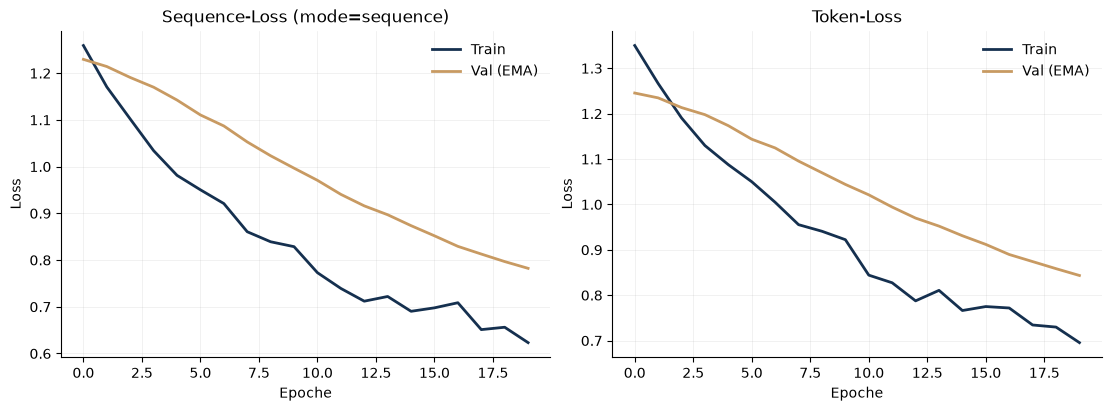

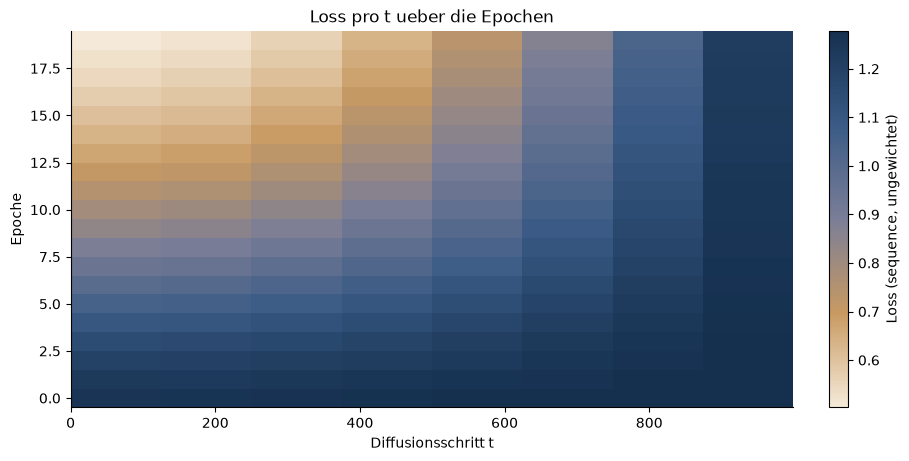

In [10]:
#==Testlauf==
history = trainer.fit(token_loss=True)

figs = trainer.summarize_eval(show=True)
pdf = trainer.print_report()

print("\n==== Erzeugt ====")
for pfad in sorted(run_manager.run_dir.rglob("*")):
    if pfad.is_file():
        print(f"  {pfad.relative_to(run_manager.run_dir)}  ({pfad.stat().st_size / 1e3:.1f} kB)")

print("\nhistory-Keys:", list(history))
print("loss_per_t-Matrix:", tuple(torch.stack(history["loss_per_t"]).shape), "(Epochen, t-Raster)")
print("PDF:", pdf)
